# Detecting Deception from Speech: True vs. Fabricated Stories

Can a classifier tell a true story from a made-up one using only acoustic features? Audio from the public MLEnd Deception dataset is split into 30-second segments, described with MFCC, pitch, energy and spectral statistics, and classified with SVM, Random Forest and XGBoost, followed by feature selection and Optuna tuning.


# 2 Problem formulation

The machine learning problem we have here is that we have a dataset of 100 audio recordings in our hands. These audio recordings contain 2 minute length stories in different languages. Some of the stories are true but some of them are deceptive stories. The aim of the problem is to identify which stories are true and which are deceptive. By the diversity of languages in the dataset, it presents a rather interesting problem classifying them. Like an universal lie-detector machine.

This problem is important in the real life as well. In law enforcement these techniques are sometimes used. We see in social media about lie detectors using the suspects' heartbeat and different metrics for detecting lies. But this is not the case here. We are dealing with audio recordings. And the features that lie within the audio, such as pitch, intonation and speech dynamics. Our diversity of languages makes it a challenging problem. We need to find a way to extract the features from the audio without taking the context into consideration, only audio processing.

This classifies as a supervised learning problem, since in the metadata file we are aware of the true outcome of each story. The aim is to build a model that can handle subtle differences in tone or pitch to identify the correctness of the story.

# 3 Methodology

The methodology is based on the following steps:
1. **Data collection**
The data is collected from the students of the course. The stories are labeled either "true" or "deceptive".
2. **Data preprocessing and Feature Engineering**: Preprocessing involved several steps:  
    * **Data Splitting**: The dataset is split into training, validation and test sets to evaluate the model's performance in a proper way. The splits are stratified to ensure that the proportion of true and deceptive stories in each set is the same as in the original. Also no overlap between the sets is checked.
        - **Training Set**:60% of the data  
        - **Validation Set**:20% of the data  
        - **Test Set**:20% of the data  
    * **Audio Splitting**: Splitting the audio data into 30 second chunks and also discarding recordings shorter than 30 seconds.
    * **Feature Extraction**: Acoustic features are extracted from the 30 second audio chunks using the library **Librosa**. The features are:
        - **MFCCs**: Mel-frequency cepstral coefficients (mean and variance)  
        - **Spectral Features**: Centroid, bandwith, contrast, flatness  
        - **Pitch**: Mean and standard deviation of the pitch  
        - **Power**: Average power of the signal  
    The extracted features are stored as a NumPy matrix with shape (n_samples, n_features) where n_samples is the number of audio chunks and n_features is the number of features extracted from each chunk.
    * **Metadata Retention**: During the preprocessing step, metadata for each set (train, validation, test) is retained to be used later. This helps us gain insights after the model is trained.
    * **Feature Scaling and Label Encoding**: To prepare the features for analysis, they are standardized by StandardScaler. This step ensures all features share a similar scale, which is crucial for improving the performance of many machine learning models. Additionally, the target labels "true_story" and "deceptive_story" are converted into binary values 0 for "true_story" and 1 for "deceptive_story" using LabelEncoder. This is done becuase classifiers are typically trained on binary targets.
3. **Model Training and Evaluation**: 
    * **Model Selection**:Chosen models for this project are:    
        - **Random Forest Classifier**   
        - **Support Vector Machine (SVM)** 
        - **XGBoostClassifier** 
        - **Logistic Regression**  
        - **KNNClassifier**   
    The target variable of our dataset is predicting whether a story is true or deceptive. RandomForest performed the best, so it's used as the final model.
    * **Feature Selection**: To improve the model's efficiency and prevent it from overfitting, feature importance is calculated using the RandomForestClassifier. The features which have more than 3% accuracy are kept. This also helps to reduce the dimensionality of the data.
    * **Hyperparameter Tuning**: The selected features were used to train and optimize the Random Forest model using Optuna. Objective function is set as the AUC. The best hyperparameters are selected based on the highest AUC score.
    * **Hyperparameters Tuned**:
        - **Number of trees (n_estimators)**
        - **Maximum tree depth (max_depth)**
        - **Minimum samples for splits and leaves (min_samples_split and min_samples_leaf)**
        - **Bootstrapping (bootstrap)**
        - **Class weighting (class_weight)**
    * **Final Model Evaluation**:After fine-tuning the Random Forest model through hyperparameter optimization, its performance was evaluated on the test set to determine how well it generalizes to unseen data. Rows that were misclassified during this evaluation were flagged, and their metadata, such as the language of the input, was examined. This analysis helped to discover insights.  
4. **Model performance metrics**:Performance is defined using metrics:  
    * **Accuracy**: Proportion of correctly classified samples.  
    * **Precision**: Proportion of true positives among predicted positives.  
    * **Recall**: Proportion of true positives among actual positives.  
    * **F1 Score**: Harmonic mean of precision and recall.  
    * **AUC (Area Under the ROC Curve)**: Evaluates the model's ability to distinguish between classes at different thresholds.  
    Also confusion matrices are generated to visualize the performance and identify misclassification patterns. The objective function I decided to use is AUC because in my opinion it is the most robust metric for binary classification problems. The best model is selected based on the highest AUC value. It also takes consideration of precision and recall unlike just using accuracy.

# 4 Implemented ML prediction pipelines

The machine learning pipeline for this task follows a series of clearly defined stages, each aimed at processing audio data, extracting important features, and constructing predictive models for classification. These stages work together in a structured way, converting raw data into actionable insights and accurate predictions.

+ **Input**: 2 minute audio recordings and their corresponding metadata (language and label)
+ **Output**: Binary classification prediction of each story.
+ **Intermediate Formats**:  
    - Extracted features in a NumPy array with the labels
    - Generated probability scores from the model (y_pred_proba) and binary predictions (y_pred)

This designs' modular structure allows flexibility and most of all, ease of troubleshooting or debugging.

## 4.1 Transformation stage

The transformation stage focuses on preparing the raw audio data for modeling. This involves splitting the audio into manageable segments, extracting relevant features, and scaling the features for consistent input to the models.

+ **Input**: Audio files and metadata (language and label)
+ **Output**:  
    - **Feature matrix (x)** with extracted features  
    - **Target vector (y)** consisting of 1 and 0 values representign "true" and "deceptive".


* **Steps in the Transformation Stage**:

    - **Audio Splitting**: Each audio file is split into 30-second segments to create uniform input lengths. Recordings shorter than 30 seconds are discarded.
    - **Feature Extraction**: Features are extracted using **Librosa** to capture the acoustic properties of the audio. Features include MFCCs (mean and variance), spectral properties, pitch, and power.
    - **Metadata Retention**: Metadata (language and filenames) is mapped to each segment to enable post-modeling analysis.
    - **Scaling and Encoding**: Features are scaled using StandardScaler to keep in the same ranges. The labels are encoded for binary classification.

## 4.2 Model stage

During the modeling stage, multiple machine learning algorithms were tested to find the most effective approach for the binary classification task of distinguishing true stories from deceptive ones. The models were selected based on their strengths in handling high-dimensional features, their reliability, and their ability to provide meaningful insights in audio-based classification scenarios. Here's a summary of the models explored and the reasons they were chosen:

* **Random Forest Classifier**:
    Random forests are ensemble methods that are effective for tabular datasets like those extracted from audio recordings. They are robust to overfitting and provide feature importance scores, which help in feature selection and interpretability. Additionally, their ability to handle class imbalance through class weighting is beneficial in this task.  
        - **Strengths**:  
            - Handles non-linear relationships effectively  
            - Can capture interactions between features  
            - Robust to noisy features and overfitting  
* **Support Vector Machine (SVM)**:  
    SVMs are powerful for binary classification tasks, especially in cases where the data is not linearly separable, which is expected in audio-based datasets.  
        - **Strengths**:  
            - Effective for small to medium-sized datasets  
            - Strong theoretical foundation and robust to outliers  
* **XGBoost Classifier**:  
    XGBoost is a gradient-boosting framework known for its speed and performance. It is particularly effective in handling imbalanced datasets and can handle missing values automatically.  
        - **Strengths**:  
            - Provides optimal results with low costs    
            - Includes regularization. Which prevents overfitting  
* **Logistic Regression**:  
    Logistic regression provides a simple model for binary classification problems. It is a linear and basic model.  
        - **Strengths**:  
            - Fast to train and evaluate  
            - Easy to implement  
* **K-Nearest Neighbors (KNN)**:  
        KNN is a distance based algorithm. It can provide insights into the local structure of the data.  
        - **Strengths**:  
            -Simplicity

#### **Model Selection**  
Each model was trained and evaluated using a validation set. The performance was assessed using metrics such as AUC, accuracy, precision, recall, and F1 score. Optuna is used as a trial based optimizer to perform hyperparameter tuning after best performing model, in our case **Random Forest Classifier**, is selected. The best model is selected based on the highest AUC score. 


## 4.3 Ensemble stage

This pipeline does not include ensemble methods other than the Random Forest model. Instead, the focus is on optimizing the performance of this single model. By using hyperparameter tuning and selecting the most important features, the Random Forest becomes more reliable and accurate, so there’s no need to bring in other ensemble techniques.

# 5 Dataset


**Data Loading**:
Metadata with details like language and story type was loaded into a pandas DataFrame and matched with audio files to create a complete dataset.  

**Dataset Splitting**:
The data was split into three parts:
    - **Training (60%)**: To train the model.
    - **Validation (20%)**: For tuning and testing during development.
    - **Test (20%)**: For final evaluation.
Splits were stratified to prevent class imbalance.

**Final Check**:
The number of files in each group was printed to confirm everything was evenly distributed.

**Paths:** set the audio folder and metadata CSV paths in the next cell to wherever you downloaded the MLEnd Deception dataset.


In [ ]:
! pip install librosa

In [ ]:
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split

# csv file loading
csv_path = "Deception/MLEndDD_story_attributes_small.csv"
data = pd.read_csv(csv_path)

# joining audio files with metadata
audio_dir = "Deception/MLEndDD_stories_small"
audio_files = [f for f in os.listdir(audio_dir) if f.endswith('.wav')]
data['File'] = audio_files  # Assuming the file names in CSV match exactly



# splitting
train_files, temp_files = train_test_split(
    audio_files, test_size=0.4, random_state=42, stratify=data['Story_type']
)
val_files, test_files = train_test_split(
    temp_files, test_size=0.5, random_state=42, stratify=data[data['File'].isin(temp_files)]['Story_type']
)

# aftermath
print(f"Train files: {len(train_files)}, Validation files: {len(val_files)}, Test files: {len(test_files)}")


Train files: 60, Validation files: 20, Test files: 20


In [ ]:
import librosa
import numpy as np
from tqdm import tqdm

# splits the audio into 30 second chunks and discards shorter chunks.
def split_audio(file_path, segment_length=30, sr=22050):
    y, sr = librosa.load(file_path, sr=sr)
    segment_samples = segment_length * sr
    segments = [y[i:i+segment_samples] for i in range(0, len(y), segment_samples)]
    return [seg for seg in segments if len(seg) == segment_samples]
def extract_features_advanced(audio_segment, sr=22050, silence_threshold=1e-4):
    # checking if the audio is empty
    if np.max(np.abs(audio_segment)) < silence_threshold:
        print("Empty segment")
        # returns zero for all features
        return [0] * 21  
    # normalize audio
    audio_segment = audio_segment / np.max(np.abs(audio_segment))
    # feature engineering
    power = np.sum(audio_segment**2) / len(audio_segment)
    try:
        f0, voiced_flag, _ = librosa.pyin(y=audio_segment, fmin=80, fmax=450, sr=sr)
        pitch_mean = np.nanmean(f0) if np.any(~np.isnan(f0)) else 0
        pitch_std = np.nanstd(f0) if np.any(~np.isnan(f0)) else 0
        voiced_fr = np.mean(voiced_flag) if np.any(voiced_flag) else 0
    # exception handling (lost too much time here, got some help from stackoverflow)
    except Exception as e:
        print(f"Warning! Pitch extraction failed: {e}")
        pitch_mean, pitch_std, voiced_fr = 0, 0, 0
    spectral_centroid = np.mean(librosa.feature.spectral_centroid(y=audio_segment, sr=sr))
    spectral_bandwidth = np.mean(librosa.feature.spectral_bandwidth(y=audio_segment, sr=sr))
    spectral_contrast = np.mean(librosa.feature.spectral_contrast(y=audio_segment, sr=sr))
    spectral_flatness = np.mean(librosa.feature.spectral_flatness(y=audio_segment))
    mfccs = librosa.feature.mfcc(y=audio_segment, sr=sr, n_mfcc=13)
    mfccs_mean = np.mean(mfccs, axis=1)
    mfccs_var = np.var(mfccs, axis=1)
    # merging all the features
    features = [power, pitch_mean, pitch_std, voiced_fr, spectral_centroid, spectral_bandwidth, spectral_contrast, spectral_flatness]
    features.extend(mfccs_mean)
    features.extend(mfccs_var)
    return features
# process the dataset by splitting audio into valid segments and extracting features
def process_dataset(file_list, metadata, audio_dir, segment_length=30, sr=22050):
    feature_list = []
    labels = []
    valid_files = []
    metadata_records = []

    for file in tqdm(file_list):
        file_path = os.path.join(audio_dir, file)
        # split into 30-second chunks
        segments = split_audio(file_path, segment_length, sr)  
        # extract features for each valid segment
        for segment in segments:
            features = extract_features_advanced(segment)
            feature_list.append(features)
        # append the corresponding label for each valid file
        label = metadata[metadata['File'] == file]['Story_type'].values
        # repeat the label for each segment
        labels.extend([label[0]] * len(segments))  
        # track processed files
        valid_files.append(file)  
        # add metadata record for each segment
        language = metadata.loc[metadata['File'] == file, 'Language'].values
        metadata_records.extend(
            [{'File': file, 'Language': language[0] if len(language) > 0 else "Unknown"}] * len(segments)
        )
    # update metadata to include only valid files
    updated_metadata = metadata[metadata['File'].isin(valid_files)]
    # metadata df creation
    metadata_df = pd.DataFrame(metadata_records)

    return np.array(feature_list), np.array(labels), updated_metadata, metadata_df

# function calling for preprocessing
X_train, y_train, train_metadata, train_metadata_records = process_dataset(
    train_files, data[data['File'].isin(train_files)], audio_dir
)
X_val, y_val, val_metadata, val_metadata_records = process_dataset(
    val_files, data[data['File'].isin(val_files)], audio_dir
)
X_test, y_test, test_metadata, test_metadata_records = process_dataset(
    test_files, data[data['File'].isin(test_files)], audio_dir
)

        File Language
0  00018.wav  English
1  00018.wav  English
2  00018.wav  English
3  00018.wav  English
4  00025.wav  English


Checking data overlap between sets. Encountered 100% AUC doing model selection so this control was more than useful.

In [ ]:
from collections import Counter

# checking no data overlap between sets
assert set(train_metadata['File']).isdisjoint(val_metadata['File']), "Overlap between training and validation"
assert set(train_metadata['File']).isdisjoint(test_metadata['File']), "Overlap between training and test"
assert set(val_metadata['File']).isdisjoint(test_metadata['File']), "Overlap between validation and test"

# class imbalance check
print("Training classes:", Counter(y_train))
print("Validation classes:", Counter(y_val))
print("Test classes:", Counter(y_test))

Training classes: Counter({'true_story': 130, 'deceptive_story': 117})
Validation classes: Counter({'deceptive_story': 52, 'true_story': 34})
Test classes: Counter({'true_story': 55, 'deceptive_story': 32})


**Visualizing feature behavior with subplots**

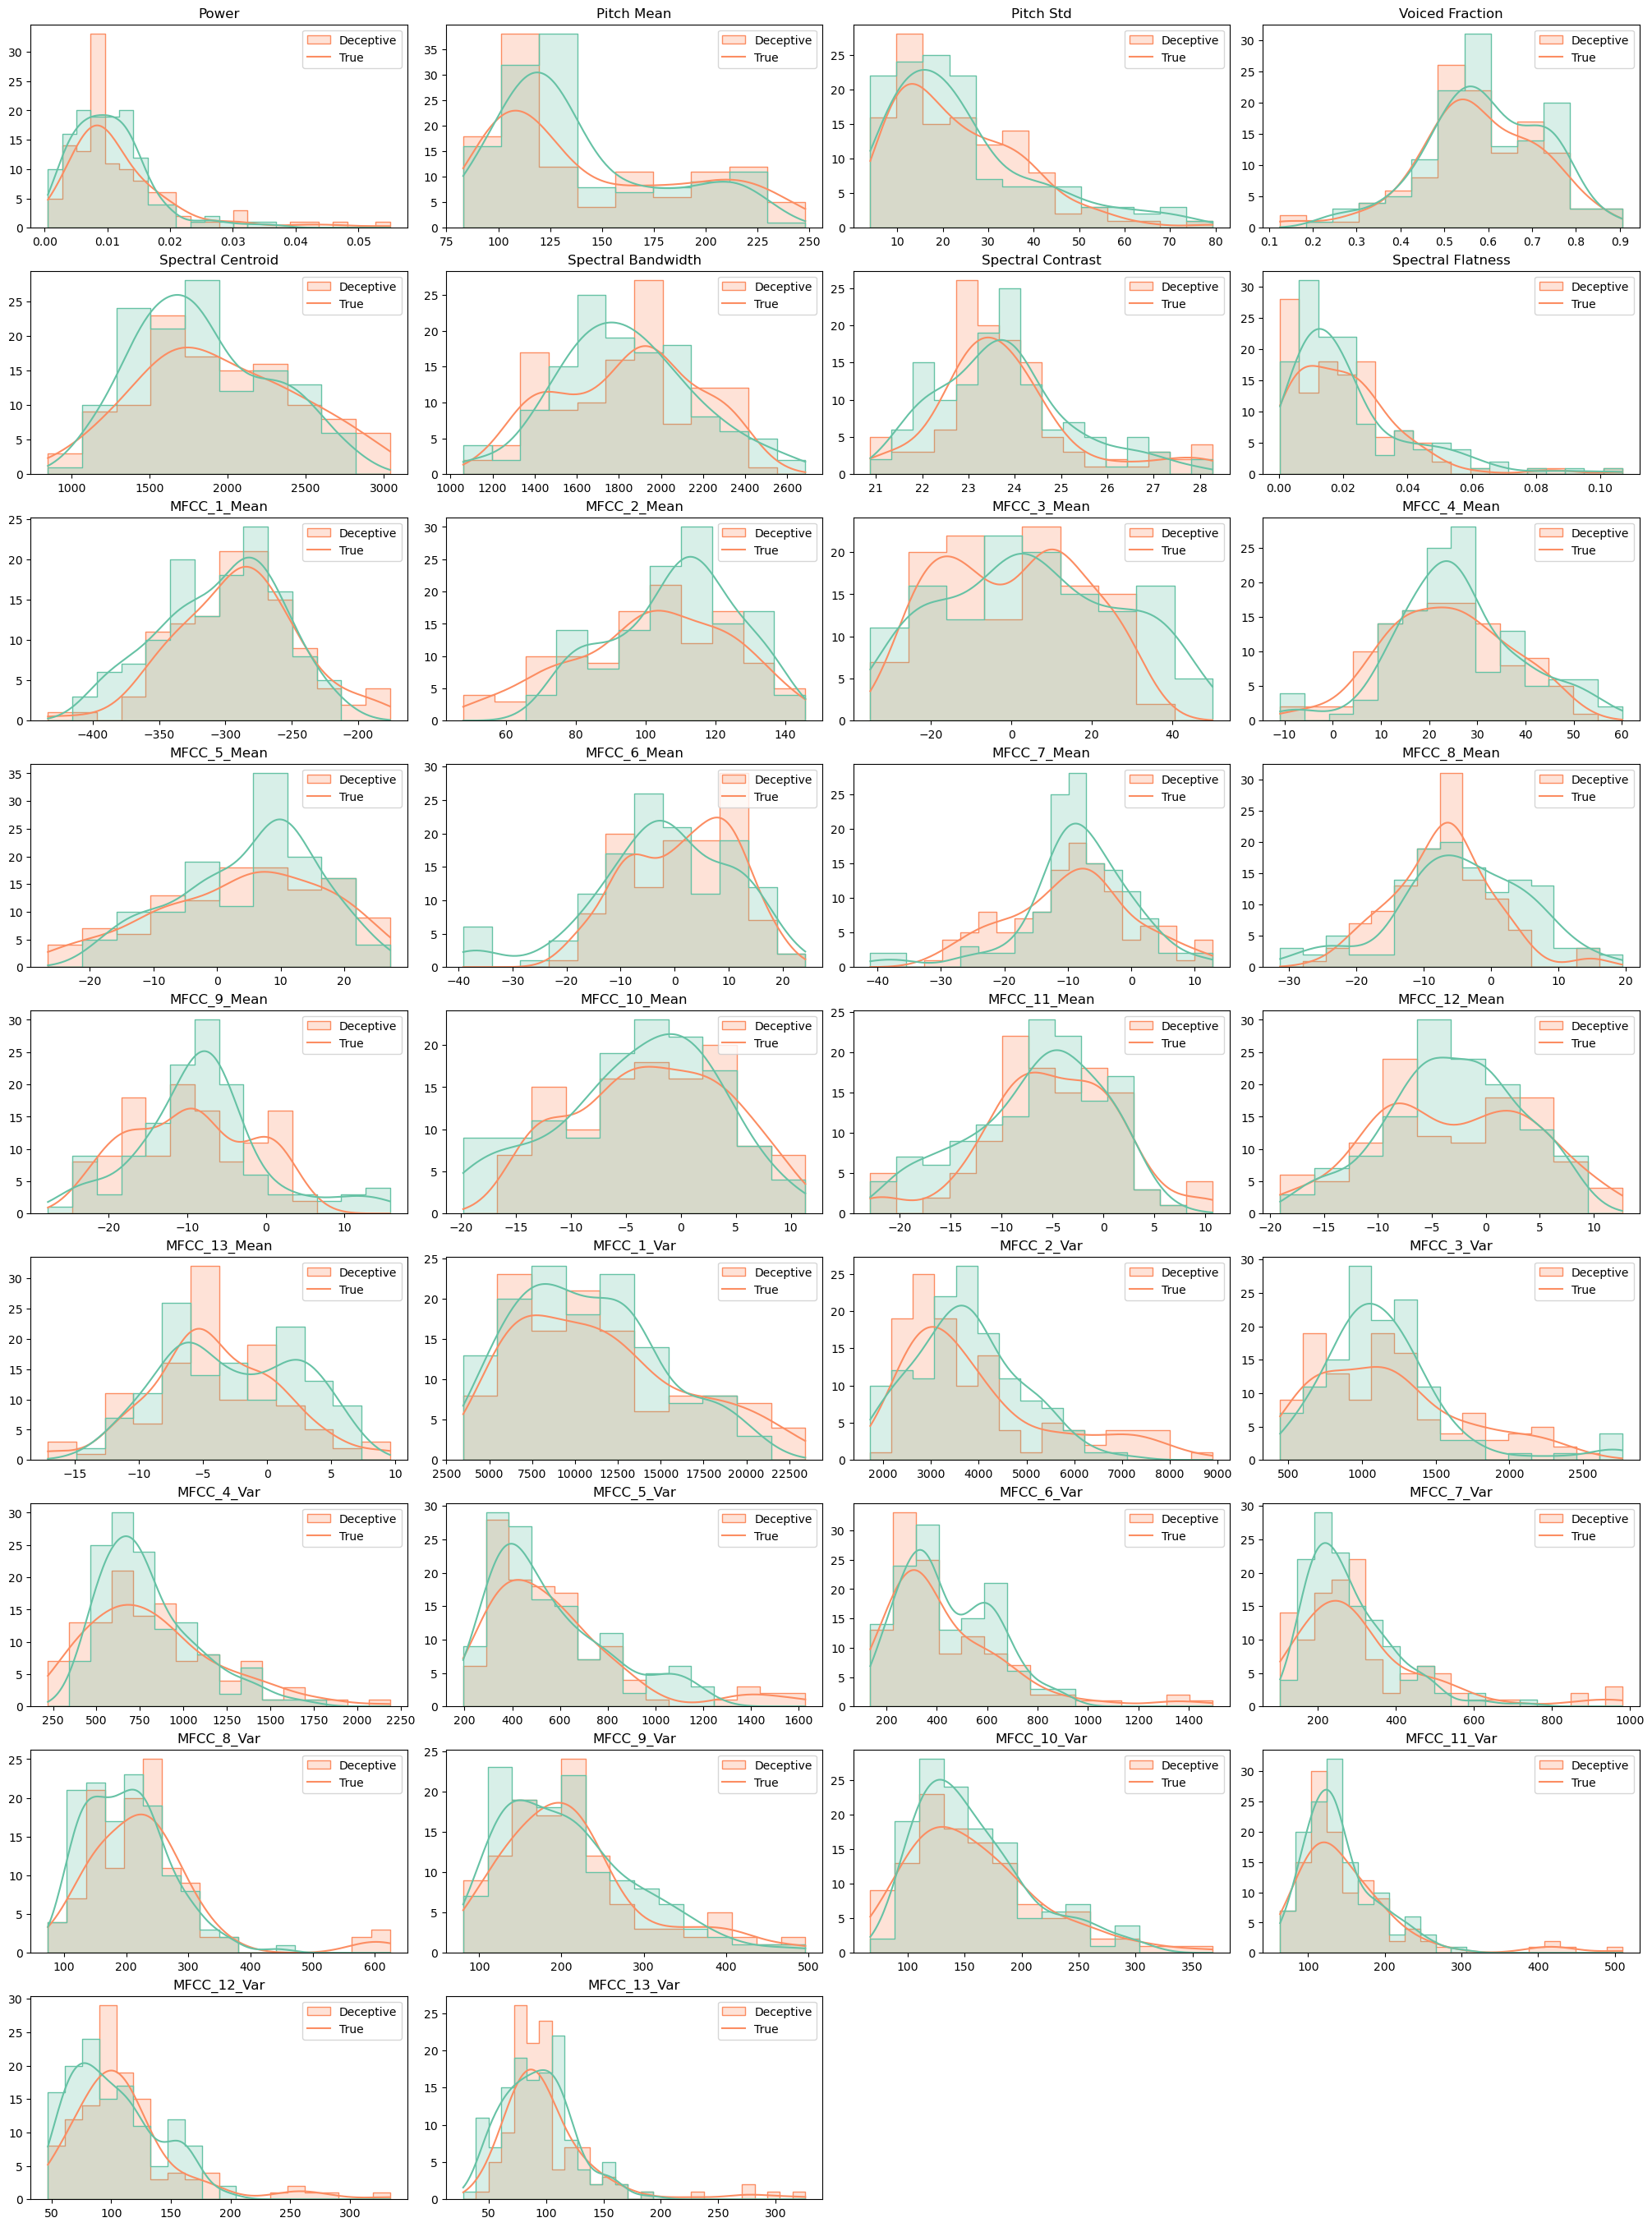

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

feature_names = [
    "Power", "Pitch Mean", "Pitch Std", "Voiced Fraction",
    "Spectral Centroid", "Spectral Bandwidth", "Spectral Contrast", "Spectral Flatness"
] + [f"MFCC_{i+1}_Mean" for i in range(13)] + [f"MFCC_{i+1}_Var" for i in range(13)]

features_df = pd.DataFrame(X_train, columns=feature_names)
features_df['Story_type'] = y_train  # Append labels

# plot feature distribution for true and deceptive stories
n_features = len(feature_names)
rows = n_features // 4 + (n_features % 4 != 0)
fig, axes = plt.subplots(rows, 4, figsize=(20, 3 * rows), constrained_layout=True)
axes = axes.flatten()

for i, col in enumerate(feature_names):
    sns.histplot(data=features_df, x=col, hue='Story_type', kde=True, palette='Set2', element="step", ax=axes[i])
    axes[i].set_title(f"{col}")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].legend(["Deceptive", "True"], loc='upper right')

# turn off unused subplots
for ax in axes[n_features:]:
    ax.axis('off')

plt.show()


For features like MFCC9 Mean, MFCC 2 Mean and MFCC8 Mean the diversion between true and deceptive stories are visually seperable. But features like MFCC 12 Var and Power, they are indistingiushable.

Training classes: True = 130, Deceptive = 117
Validation classes: True = 34, Deceptive = 52


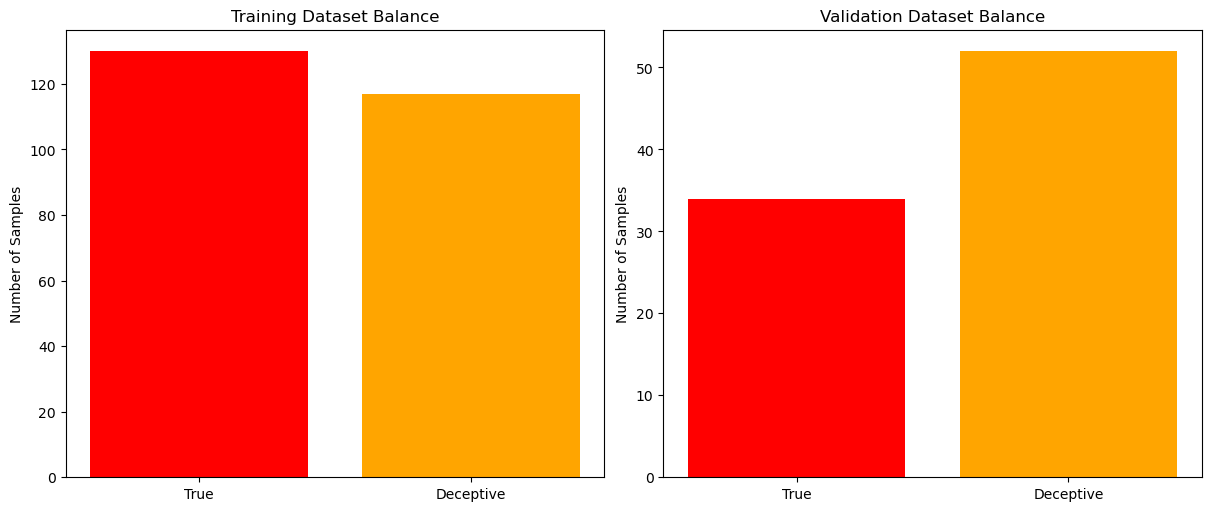

In [ ]:
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import numpy as np

from sklearn.preprocessing import StandardScaler

# normalization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# label encoding for y
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)
y_val_encoded = encoder.transform(y_val)
y_test_encoded = encoder.transform(y_test)

# dataset balance check
train_true_count = np.sum(y_train_encoded)
train_false_count = len(y_train_encoded) - train_true_count

val_true_count = np.sum(y_val_encoded)
val_false_count = len(y_val_encoded) - val_true_count

print(f"Training classes: True = {train_true_count}, Deceptive = {train_false_count}")
print(f"Validation classes: True = {val_true_count}, Deceptive = {val_false_count}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

# training set balance
axes[0].bar(['True', 'Deceptive'], [train_true_count, train_false_count], color=['red', 'orange'])
axes[0].set_title("Training Dataset Balance")
axes[0].set_ylabel("Number of Samples")

# validation
axes[1].bar(['True', 'Deceptive'], [val_true_count, val_false_count], color=['red', 'orange'])
axes[1].set_title("Validation Dataset Balance")
axes[1].set_ylabel("Number of Samples")

plt.show()


After visualizing the balance for training and validation. There is no major concern for class imbalance. The validation set has 37% True labels but it's not a major imbalance problem.

# 6 Experiments and results

In [7]:
! pip install optuna xgboost

In [ ]:
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# chosen models
models = {
    'SVM': SVC(probability=True, random_state=42),
    'RandomForest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    'LogisticRegression': LogisticRegression(random_state=42),
    'KNN': KNeighborsClassifier()
}

# dictionary to store results
baseline_results = {}

for model_name, model in models.items():
    print(f"Evaluating {model_name}...")
    model.fit(X_train_scaled, y_train_encoded) 
    
    #checking if model has predict_proba method
    if hasattr(model, 'predict_proba'):
        y_val_pred_prob = model.predict_proba(X_val_scaled)[:, 1]
    else:
        y_val_pred_prob = model.decision_function(X_val_scaled)
    
    # turning probabilities into binaries
    y_val_pred = (y_val_pred_prob > 0.5).astype(int)
    
    # evaluation metric calculation
    auc = roc_auc_score(y_val_encoded, y_val_pred_prob)
    accuracy = accuracy_score(y_val_encoded, y_val_pred)
    precision = precision_score(y_val_encoded, y_val_pred, zero_division=0)
    recall = recall_score(y_val_encoded, y_val_pred, zero_division=0)
    f1 = f1_score(y_val_encoded, y_val_pred, zero_division=0)
    
    # results
    baseline_results[model_name] = {
        'AUC': auc,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    }
    #printing
    print(f"{model_name} Metrics: AUC = {auc:.4f}, Accuracy = {accuracy:.4f}, Precision = {precision:.4f}, Recall = {recall:.4f}, F1 Score = {f1:.4f}")

# selecting the best model based on AUC
best_model_name = max(baseline_results, key=lambda k: baseline_results[k]['AUC'])
print(f"Best model based on AUC: {best_model_name}")


Evaluating SVM...
SVM Metrics: AUC = 0.4180, Accuracy = 0.3837, Precision = 0.2791, Recall = 0.3529, F1 Score = 0.3117
Evaluating RandomForest...
RandomForest Metrics: AUC = 0.5461, Accuracy = 0.5116, Precision = 0.4167, Recall = 0.5882, F1 Score = 0.4878
Evaluating XGBoost...


XGBoost Metrics: AUC = 0.3071, Accuracy = 0.3372, Precision = 0.2444, Recall = 0.3235, F1 Score = 0.2785
Evaluating LogisticRegression...
LogisticRegression Metrics: AUC = 0.4842, Accuracy = 0.5116, Precision = 0.4259, Recall = 0.6765, F1 Score = 0.5227
Evaluating KNN...
KNN Metrics: AUC = 0.4825, Accuracy = 0.3953, Precision = 0.3500, Recall = 0.6176, F1 Score = 0.4468
Best model based on AUC: RandomForest


As stated above, RandomForest performed best for this problem and this dataset. Also it's the only model that has more than 50% on accuracy and AUC. Since XGBoost is not tuned, it performed the worst, since it heavily relies on hyperparameters. Notably, Logistic Regression performed rather well compared to other models considering it's the simplest model of them all. 

#### **Feature Selection**

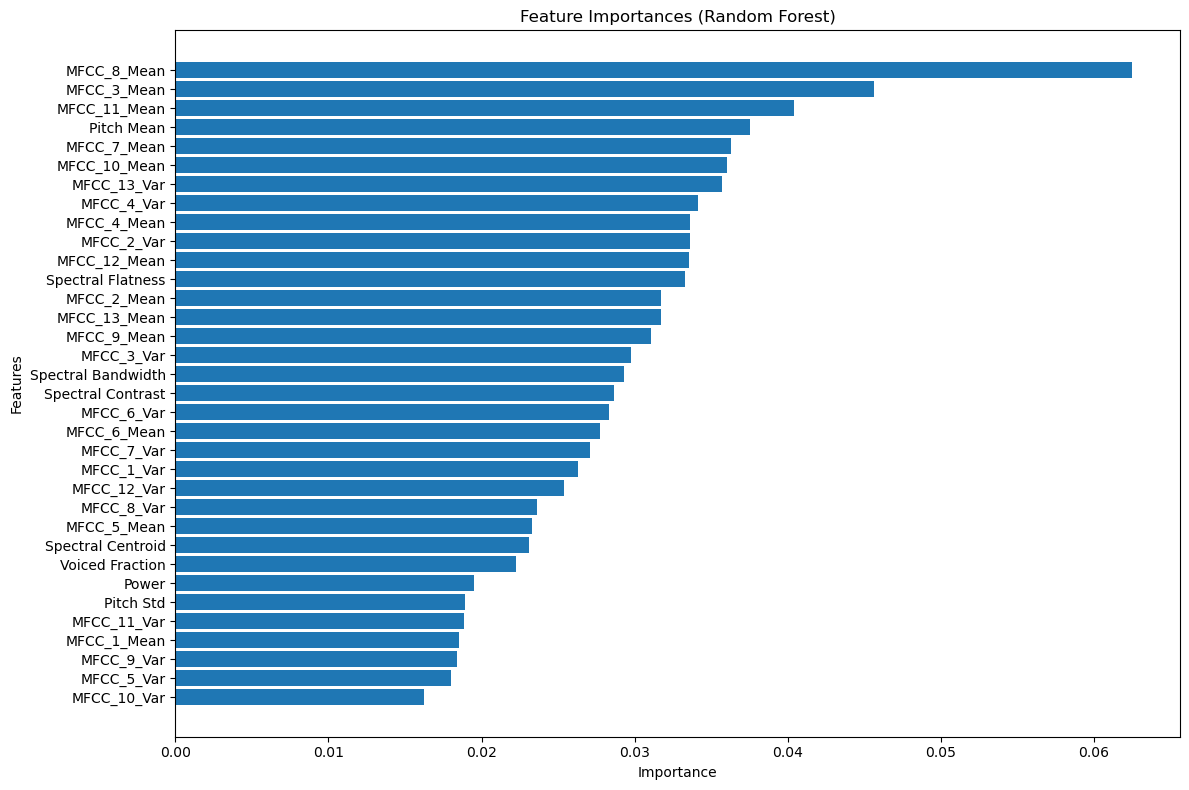

Features sorted by importance:
               Feature  Importance
15         MFCC_8_Mean    0.062495
10         MFCC_3_Mean    0.045617
18        MFCC_11_Mean    0.040401
1           Pitch Mean    0.037555
14         MFCC_7_Mean    0.036301
17        MFCC_10_Mean    0.036026
33         MFCC_13_Var    0.035735
24          MFCC_4_Var    0.034142
11         MFCC_4_Mean    0.033628
22          MFCC_2_Var    0.033599
19        MFCC_12_Mean    0.033522
7    Spectral Flatness    0.033311
9          MFCC_2_Mean    0.031714
20        MFCC_13_Mean    0.031713
16         MFCC_9_Mean    0.031047
23          MFCC_3_Var    0.029746
5   Spectral Bandwidth    0.029302
6    Spectral Contrast    0.028669
26          MFCC_6_Var    0.028325
13         MFCC_6_Mean    0.027749
27          MFCC_7_Var    0.027070
21          MFCC_1_Var    0.026286
32         MFCC_12_Var    0.025390
28          MFCC_8_Var    0.023643
12         MFCC_5_Mean    0.023273
4    Spectral Centroid    0.023123
3      Voiced Fraction  

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

# model training
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train_encoded)

# getting the feature names as they are in matrix form now
feature_names = [
    "Power", "Pitch Mean", "Pitch Std", "Voiced Fraction",
    "Spectral Centroid", "Spectral Bandwidth", "Spectral Contrast", "Spectral Flatness"
] + [f"MFCC_{i+1}_Mean" for i in range(13)] + [f"MFCC_{i+1}_Var" for i in range(13)]
importances = rf.feature_importances_
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# feature importance plot
plt.figure(figsize=(12, 8))
plt.barh(importance_df['Feature'][::-1], importance_df['Importance'][::-1])
plt.title("Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# printing the feature importance
print(f"Features sorted by importance:\n{importance_df}")


After observing the values for feature importance, I chose a threshold of 3% to select the important features. This threshold is somewhat arbitrary, but it seems reasonable given the distribution of feature importance values.

In [ ]:
# selecting features with importance >= 0.03
selected_features = importance_df[importance_df['Importance'] >= 0.03]['Feature'].values

# selecting only important features
X_train_selected = pd.DataFrame(X_train_scaled, columns=feature_names)[selected_features].values
X_val_selected = pd.DataFrame(X_val_scaled, columns=feature_names)[selected_features].values
X_test_selected = pd.DataFrame(X_test_scaled, columns=feature_names)[selected_features].values

#printing the important features
print(f"Selected Features: {selected_features}")

Selected Features: ['MFCC_8_Mean' 'MFCC_3_Mean' 'MFCC_11_Mean' 'Pitch Mean' 'MFCC_7_Mean'
 'MFCC_10_Mean' 'MFCC_13_Var' 'MFCC_4_Var' 'MFCC_4_Mean' 'MFCC_2_Var'
 'MFCC_12_Mean' 'Spectral Flatness' 'MFCC_2_Mean' 'MFCC_13_Mean'
 'MFCC_9_Mean']


After applying feature selection, our feature counts dropped to 15 from 34. High dimensional datasets are not desirable when building models. More rows == Great Models but More Columns == Highly complex, hardly interpreted and less performing models. This drop in dimensionality is desired to prevent overfitting, reducing model complexity and improving interpretability. Also computational costs are significantly reduced by this step. 

#### **Objective Function**
The objective function is like a scorecard it measures how well each trial or combination of hyperparameters performs. It’s the key to figuring out which settings work best for the model.  
**Hyperparameter Search Space**  
    -**n_estimators**:Number of trees in the forest (10 to 500)  
    -**max_depth**:Maximum depth of each tree (3 to 50)  
    -**min_samples_split**:Minimum number of samples required to split an internal node (2 to 20)  
    -**min_samples_leaf**:Minimum number of samples required to form a leaf node (1 to 10)  
    -**bootstrap**:Whether to use bootstrap sampling (True or False)  
    -**class_weight**:Class balancing strategies (None, balanced, balanced_subsample)  
**Optuna**: A study is created to maximize AUC. It runs with the specified number of trials (in our case it is 500) with given hyperparameter spaces. It tries the combination of hyperparameters within the defined trial number. The evaluation metric (in our case it is AUC) is used to determine which is the best model. The best parameters are stored in the study. 

Best trial parameters: {'n_estimators': 190, 'max_depth': 3, 'min_samples_split': 14, 'min_samples_leaf': 1, 'bootstrap': False, 'class_weight': 'balanced'}
Best AUC: 0.7234162895927602
Validation Accuracy: 0.6977
Validation Precision: 0.6111
Validation Recall: 0.6471
Validation F1 Score: 0.6286


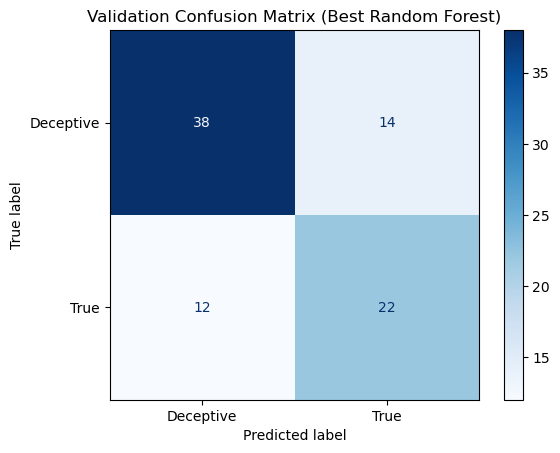

In [ ]:
import optuna
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
# objective function declaration
def objective(trial):
    # hyperparameters to tune
    n_estimators = trial.suggest_int('n_estimators', 10, 500)
    max_depth = trial.suggest_int('max_depth', 3, 50)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 20)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)
    bootstrap = trial.suggest_categorical('bootstrap', [True, False])
    class_weight = trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample'])

    rf = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        bootstrap=bootstrap,
        class_weight=class_weight,
        random_state=42
    )
    rf.fit(X_train_selected, y_train_encoded)

    # predict probabilities and binary outcomes for the validation set
    y_val_pred_prob = rf.predict_proba(X_val_selected)[:, 1]
    y_val_pred = (y_val_pred_prob > 0.5).astype(int)

    # eval metrics computation
    auc = roc_auc_score(y_val_encoded, y_val_pred_prob)
    accuracy = accuracy_score(y_val_encoded, y_val_pred)
    precision = precision_score(y_val_encoded, y_val_pred, zero_division=0)
    recall = recall_score(y_val_encoded, y_val_pred, zero_division=0)
    f1 = f1_score(y_val_encoded, y_val_pred, zero_division=0)

    # eval metrics storing is done to be available later
    trial.set_user_attr('accuracy', accuracy)
    trial.set_user_attr('precision', precision)
    trial.set_user_attr('recall', recall)
    trial.set_user_attr('f1', f1)
    trial.set_user_attr('y_pred', y_val_pred)
    trial.set_user_attr('confusion_matrix', confusion_matrix(y_val_encoded, y_val_pred))

    #optuna will maximize AUC
    return auc  

# an optuna study is created to maximize AUC
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=500)

# printing the best hyperparameters and metrics
best_trial = study.best_trial
print(f"Best trial parameters: {best_trial.params}")
print(f"Best AUC: {best_trial.value}")
print(f"Validation Accuracy: {best_trial.user_attrs['accuracy']:.4f}")
print(f"Validation Precision: {best_trial.user_attrs['precision']:.4f}")
print(f"Validation Recall: {best_trial.user_attrs['recall']:.4f}")
print(f"Validation F1 Score: {best_trial.user_attrs['f1']:.4f}")

# confusion matrix for the best model
cm = best_trial.user_attrs['confusion_matrix']
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Deceptive', 'True'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Validation Confusion Matrix (Best Random Forest)")
plt.show()


### **Validation Results Analysis**
- The model performs well when trying to classify deceptive stories with 38/52 of deceptive stories classified correctly.
- The model identified 22 true stories correctly but 12 true stories are misclassified as deceptive.
- The model has **64.71% Recall** and **61.11% Precision** which are great results considering the complexity of the task.
- The model has **0.7234 AUC** which is exceptionally good considering the hardship of the problem we have in our hands. It suggests the model has a good ability to seperate true and deceptive stories.

### **Implementing the Model on the Test Set**

Test AUC: 0.4381
Test Accuracy: 0.5057
Test Precision: 0.6500
Test Recall: 0.4727
Test F1 Score: 0.5474


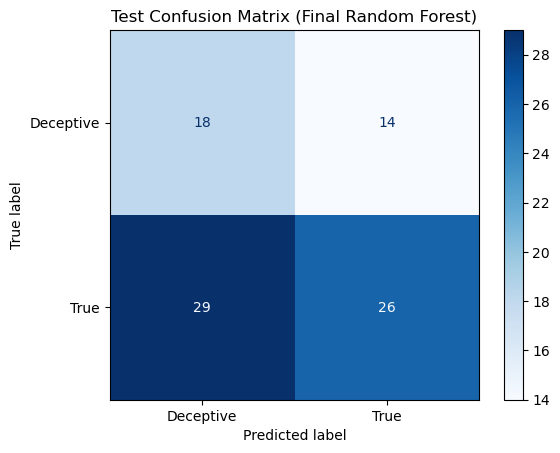

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# train the final model with the best hyperparameters
final_rf = RandomForestClassifier(
    n_estimators=best_trial.params['n_estimators'],
    max_depth=best_trial.params['max_depth'],
    min_samples_split=best_trial.params['min_samples_split'],
    min_samples_leaf=best_trial.params['min_samples_leaf'],
    bootstrap=best_trial.params['bootstrap'],
    random_state=42
)
final_rf.fit(X_train_selected, y_train_encoded)

# predict on the test set
y_test_pred = final_rf.predict(X_test_selected)
y_test_pred_prob = final_rf.predict_proba(X_test_selected)[:, 1]

# compute test set eval metrics
test_auc = roc_auc_score(y_test_encoded, y_test_pred_prob)
test_accuracy = accuracy_score(y_test_encoded, y_test_pred)
test_precision = precision_score(y_test_encoded, y_test_pred, zero_division=0)
test_recall = recall_score(y_test_encoded, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test_encoded, y_test_pred, zero_division=0)

#printing the test set metrics
print(f"Test AUC: {test_auc:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
print(f"Test F1 Score: {test_f1:.4f}")

# confusion matrix generation for test
test_cm = confusion_matrix(y_test_encoded, y_test_pred)
test_disp = ConfusionMatrixDisplay(confusion_matrix=test_cm, display_labels=['Deceptive', 'True'])
test_disp.plot(cmap=plt.cm.Blues)
plt.title("Test Confusion Matrix (Final Random Forest)")
plt.show()

#### **Test Results Analysis**
- The **precision (65.00%)** shows that when the model predicts a story as "true," it is correct 65% of the time.  
- The **recall (47.27%)** shows that the model identifies less than half of the true stories accurately, highlighting a weakness in identifying all positive cases.  
- The **accuracy (50.57%)** shows that the model is only 0.57% better than random guessing. This implies that the model is not very effective on unseen data.   
- There are **14 false positives**, where true stories were misclassified as deceptive and **29 false negatives**, where deceptive stories were classified as true. This shows that in the test set, deceptive stories' features are tricking the model, making it misclassify them as true.  
- The **AUC (0.4381)** is below 50%, showing the model doesn't perform great on unseen data. This shows that a lack of generalization in constrast to it performing great on validation set.


### **Analysis and Insights**

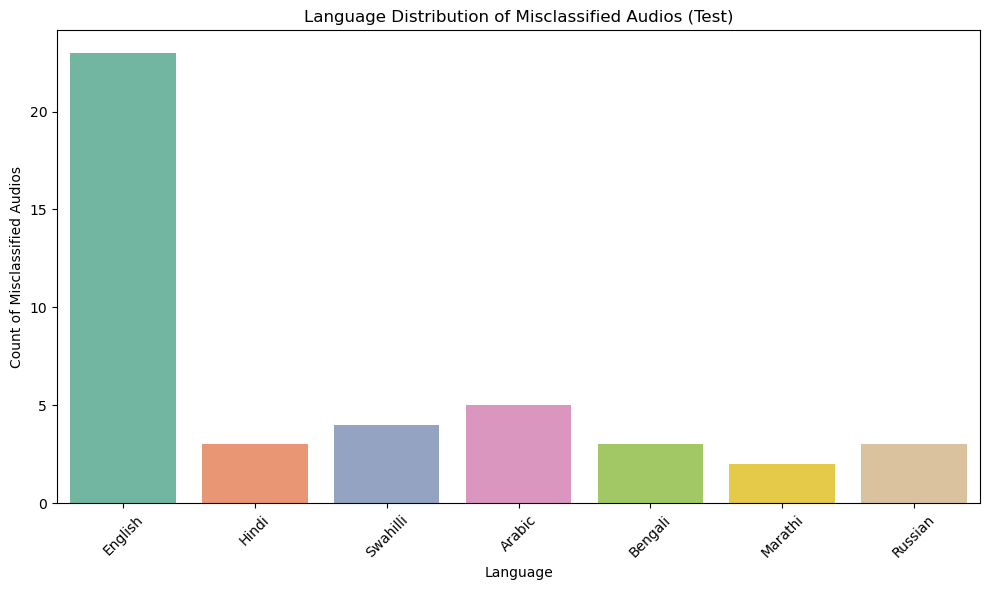

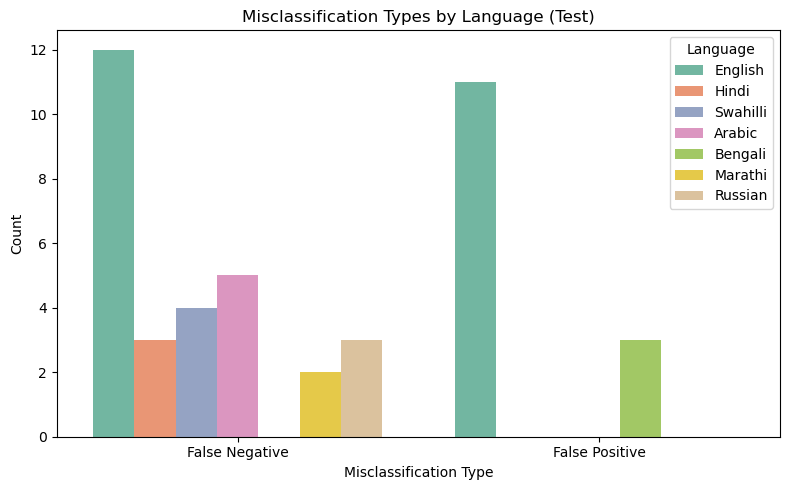

Misclassified rows for Test set exported to 'misclassified_rows_test_analysis.csv'


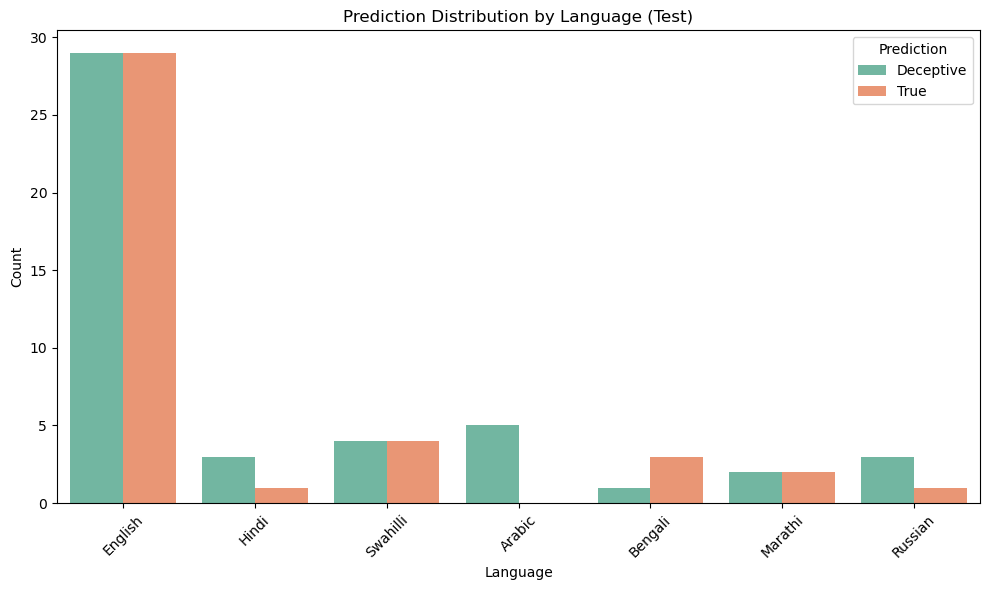

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

def analyze_results_directly(metadata, true_labels, predictions, dataset_name="Test"):
    # converting true labels and predictions to numpy arrays
    true_labels = np.array(true_labels)
    predictions = np.array(predictions)

    # adding true labels and predictions to the metadata to be analyzed later
    metadata['True_Label'] = true_labels
    metadata['Prediction'] = predictions

    # identifying the misclassified rows
    misclassified_indices = true_labels != predictions
    misclassified_metadata = metadata[misclassified_indices].copy()

    # misclassified language distribution
    if 'Language' in misclassified_metadata.columns:
        plt.figure(figsize=(10, 6))
        sns.countplot(data=misclassified_metadata, x='Language', palette='Set2')
        plt.title(f"Language Distribution of Misclassified Audios ({dataset_name})")
        plt.xlabel("Language")
        plt.ylabel("Count of Misclassified Audios")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    # true vs. deceptive misclassification ratios
    if 'True_Label' in misclassified_metadata.columns:
        misclassified_metadata['Misclassified_Type'] = misclassified_metadata.apply(
            lambda row: 'False Positive' if row['True_Label'] == 0 else 'False Negative',
            axis=1
        )

        plt.figure(figsize=(8, 5))
        sns.countplot(data=misclassified_metadata, x='Misclassified_Type', hue='Language', palette='Set2')
        plt.title(f"Misclassification Types by Language ({dataset_name})")
        plt.xlabel("Misclassification Type")
        plt.ylabel("Count")
        plt.legend(title="Language")
        plt.tight_layout()
        plt.show()

    # exporting misclassified rows to a CSV, this is a great practice after every project in terms of logging and accessign the results later on, so I implemented that
    output_file = f"misclassified_rows_{dataset_name.lower()}_analysis.csv"
    misclassified_metadata.to_csv(output_file, index=False)
    print(f"Misclassified rows for {dataset_name} set exported to '{output_file}'")

    # prediction distribution by language
    if 'Language' in metadata.columns:
        plt.figure(figsize=(10, 6))
        sns.countplot(data=metadata, x='Language', hue='Prediction', palette='Set2')
        plt.title(f"Prediction Distribution by Language ({dataset_name})")
        plt.xlabel("Language")
        plt.ylabel("Count")
        plt.legend(title="Prediction", labels=['Deceptive', 'True'])
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

# calling the above function for validation and test sets. Train set analysis is not performed because I utilized validation set for model selection. So there are no y_pred values for train set.
# analyze_results_directly(val_metadata_records, y_val_encoded, y_val_pred, dataset_name="Validation")
analyze_results_directly(test_metadata_records, y_test_encoded, y_test_pred, dataset_name="Test")


#### **Analysis and Insights on Test**
**Language Distribution of Misclassified Audios**  
- The majority of misclassified audios were in English, which dominates the dataset  
- Other languages, like Hindi, Swahili, Arabic, Bengali, Marathi, and Russian are also misclassified but not comparable to English audios.  
- This indicates that model is biased to English and tries to overfit other languages to English classifications.  

**Misclassification Types by Language**  
- The model misclassified true stories mostly in English as it's the most common langauge in the dataset, which makes sense. It's followed by Arabic, Swahili, Russian and Hindi.  
- False positives are less common as the model is more biased to classify audios as negatives based on the analysis provided. In Test set those observations consist of English and Bengali only.  
- It is observed that more hard-sounding languages like Russian and Arabic are misclassified as negatives only. These can lead insights into language phonetic characteristics since Arabic and Russian both use less vowels compared to more   balanced and soft languages like English for instance.  
- On the other hand Bengali Audios are mostly misclassified as False Positives. This can indicate that Bengali shares different phonetical components than rest of the Test dataset. 
 
**Prediction Distribution by Language**
- For English, predictions are fairly balanced between true and deceptive, but there are more misclassifications since English dominates the dataset. In contrast, languages like Hindi and Arabic have more uneven distributions, leaning heavily toward either true or deceptive predictions. This underscores the challenges tied to language differences in the model's performance.


# 7 Conclusions

The goal of this project was to classify narrated stories as "true" or "deceptive" using audio features from 30-second segments. Although the final model didn't perform that well, the results show the complexity of the task we have in hand and it provided valuable insights into language diversity in the terms of linguistics and phonetics.

#### **Key Findings**

**Model Performance**
- The chosen model, Random Forest, hyperparameter tuned using Optuna performed 0.7234 on the validation set but yielded 0.4381 on the test set. Which indicates overfitting or generalization when fitting on unseen data.
- The test set accuracy is 50.57% which is slightly better than random guessing. Suggesting the model may not be great for handling such a complex task.

**Language Challanges**
- The dominance aof English in the dataset resulted in the model leaning towards English phonetics and characteristics when trying to classify audios.
- The above mentioned point also resulted in the lack of generalization between languages.
- Misclassification types varied between languages but in general there were more False Negatives than False Positives, which is prevalent when considering the precision and recall difference in teh test dataset.  
**Test Precision: 0.6500**
**Test Recall: 0.4727**  

**Feature Importance**
- The model relied on features like MFCCs, pitch, spectral properties, and power, but these might not capture the hidden tones needed for detecting deception. Considering differences in tone and speech dynamics that differs by language,  more advanced and tailored feature extraction methods could have been used.

**Data Limitations**
- The dataset only had 100 samples. Considering I also implemented Train-Validation-Test Split, it also reduced the model to capture every interaction.   
- Also since the dataset consisted of different languages, minority languages in the dataset resulted in imbalances and sparcity.
- The lack of context or restricted the model to only determine by the sonic attributes when applying classificaiton.  

#### **Suggestions for Improvement**
**Feature Engineering:**
- If a language specific preprocessing tool is used when doing feature extraction, the model could have handled language diversity more effectively.
- Also libraries like Wav2Vec could have been utilized to capture more complex patterns within the features.
**Handling Language Imbalance:**
- Techniques like SMOTE could be utilized to generate samples to tackle the language imbalance problem that we observed after dping the analysis. 
- Also weighting could be used to improve the model's performance.
**Cross Validation:**
- Cross validation could have been used to utilize more of the data considering we only had a limited number of samples.
- Also it would have been beneficial to tackle overfitting, since we hav a significant gap between validation performance and the test performance.
**Model Selection:**
- More advanced models could have been utilized rather than RandomForest.
- In model selection if I employed a little bit hyperparameter tuning, I believe models like XGBoost could have performed better. (I also know better about XGBoost hyperparameters, but I sticked to the ebst performing model instead)        
**Incorporating Context:**
- Sentiment analysis could have been utilized to also generate a feature and it would have been beneficial since in dtaa collection we also had features like valence.
- Speaker gender could have been a feature since it's a fact that male and female sounds are phonetically diffferent.

#### **Conclusion**
This project showcases the challenges of working with audio data consisting of different languages. The results are not desirable but it helped me gain more information about working with diverse data. By utilizing the suggestion for improvements described above, the model and the results would be better net time I'm challenged with a complex task like this one. This mini project was very engaging considering we were the ones that provided the data.




# 8 References

#### -Zhang, J. (2021). Music feature extraction and classification algorithm based on deep learning. Scientific Programming, 2021, 1–9. https://doi.org/10.1155/2021/1651560  
#### -Audio feature extraction | Edge Impulse Documentation. (n.d.). https://docs.edgeimpulse.com/docs/concepts/data-engineering/audio-feature-extraction  
#### -Sharma, G. Umapathy, K. Krishnan, S. (2020). Trends in audio signal feature extraction methods. Applied Acoustics, 158. https://calebrascon.info/PDA/Topic4/addresources/features.pdf   

## **Libraries and Tools Used**
**1.Librosa:** For audio feature extraction purposes.  
**2.Pandas:** For data manipulation and analysis.  
**3.Scikit-learn:** For classification tasks, evaluation metrics and confusion matrices.  
**4.Matplotlib:** For data visualization.  
**5.Numpy:** For numerical computations and matrices.  
**6.Optuna:** For hyperparameter tuning.  
**7.TQDM:** For progress tracking.  
**8.XGBoost:** Model used for training when performing model selection.  